# Reading event files

A minimal example of how to read the events written by `scripts/generate.py`. Generate one file per channel first, from the repository root. Plots below use 100k events per tag (the default is 10k).

```bash
python scripts/generate.py d0 --n-events 100000
python scripts/generate.py b0 --n-events 100000
python scripts/generate.py bs --n-events 100000
python scripts/generate.py b0_3pi --n-events 100000
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt

CHANNELS = ["d0", "b0", "bs", "b0_3pi"]
events = {ch: np.load(f"../events_{ch}.npz") for ch in CHANNELS}   # one file per channel
DECAY = {"d0": r"$D^0\to K_S^0\pi^+\pi^-$", "b0": r"$B^0\to K_S^0\pi^+\pi^-$",
         "bs": r"$B_s^0\to K_S^0\pi^+\pi^-$", "b0_3pi": r"$B^0\to\pi^+\pi^-\pi^0$"}

def time_label(ev):
    return r"$\Delta t/\tau_B$" if ev["coherent"] else r"$t/\tau$"   # time in units of the lifetime

def decay_insert(a, ch):
    a.text(0.97, 0.95, DECAY[ch], transform=a.transAxes, ha="right", va="top")

print(events["b0"].files)   # names of the arrays in each file
# s12, s13, s23 : invariant masses squared of the daughter pairs (1,2), (1,3), (2,3) [GeV^2]
# tau           : decay time in lifetimes (for b0_3pi, the decay-time difference Delta t)
# tag           : flavour tag, +1 for P0 and -1 for P0bar

['s12', 's13', 's23', 'tau', 'tag', 'true_tag', 'index', 'channel', 'coherent', 'seed', 'n_events_per_tag', 'sigma_tau', 'mistag', 'x', 'y', 'qp', 'table_provenance']


## Dalitz plot, for each tag

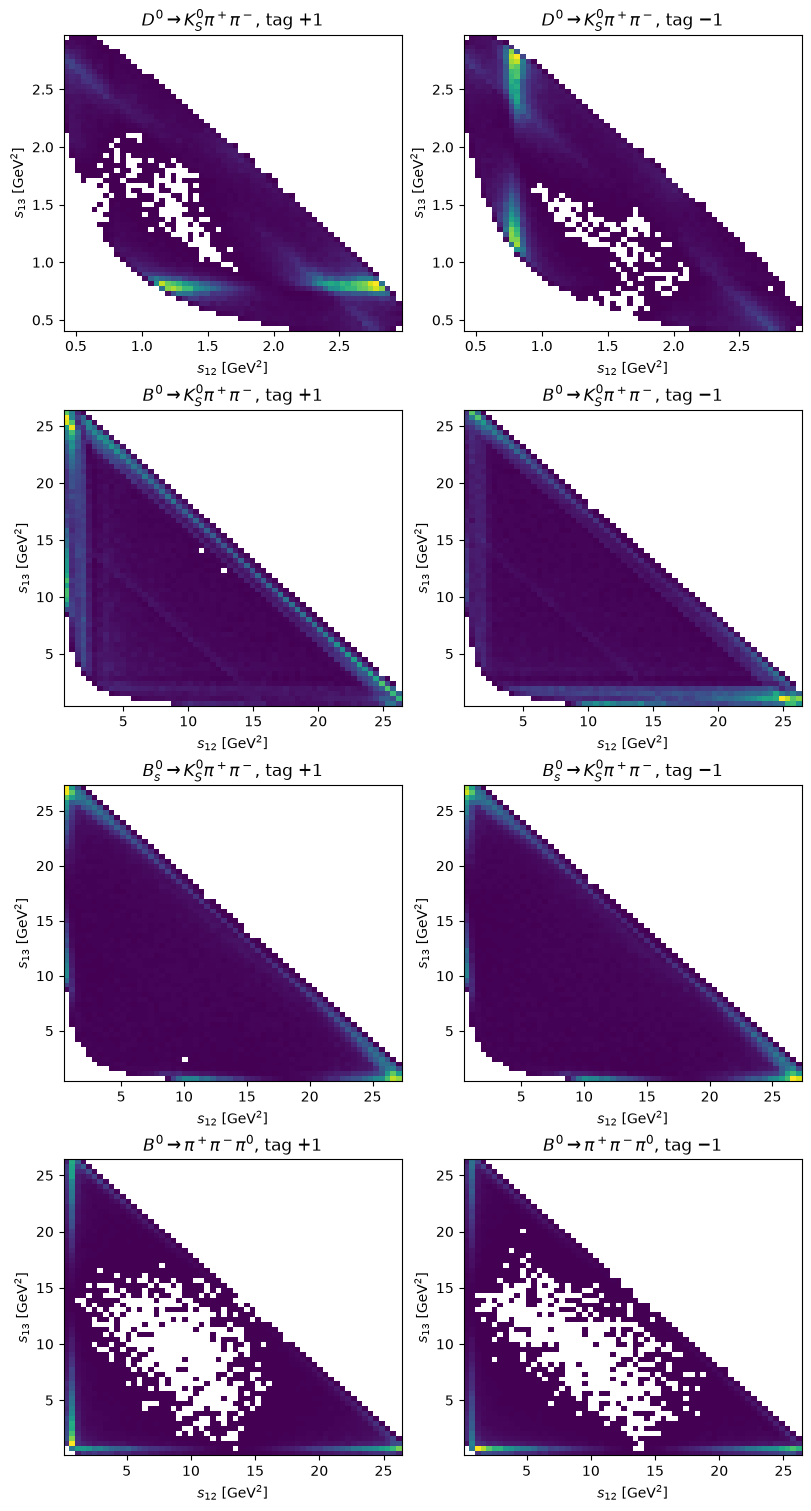

In [2]:
fig, ax = plt.subplots(len(CHANNELS), 2, figsize=(8, 15), layout="constrained")
for row, ch in zip(ax, CHANNELS):
    ev = events[ch]
    for a, t in zip(row, (+1, -1)):
        sel = ev["tag"] == t                                   # events with this tag
        a.hist2d(ev["s12"][sel], ev["s13"][sel], bins=60, cmin=1)
        a.set(title=f"{DECAY[ch]}, tag ${t:+d}$", xlabel="$s_{12}$ [GeV$^2$]", ylabel="$s_{13}$ [GeV$^2$]")
plt.show()

## Invariant-mass projections

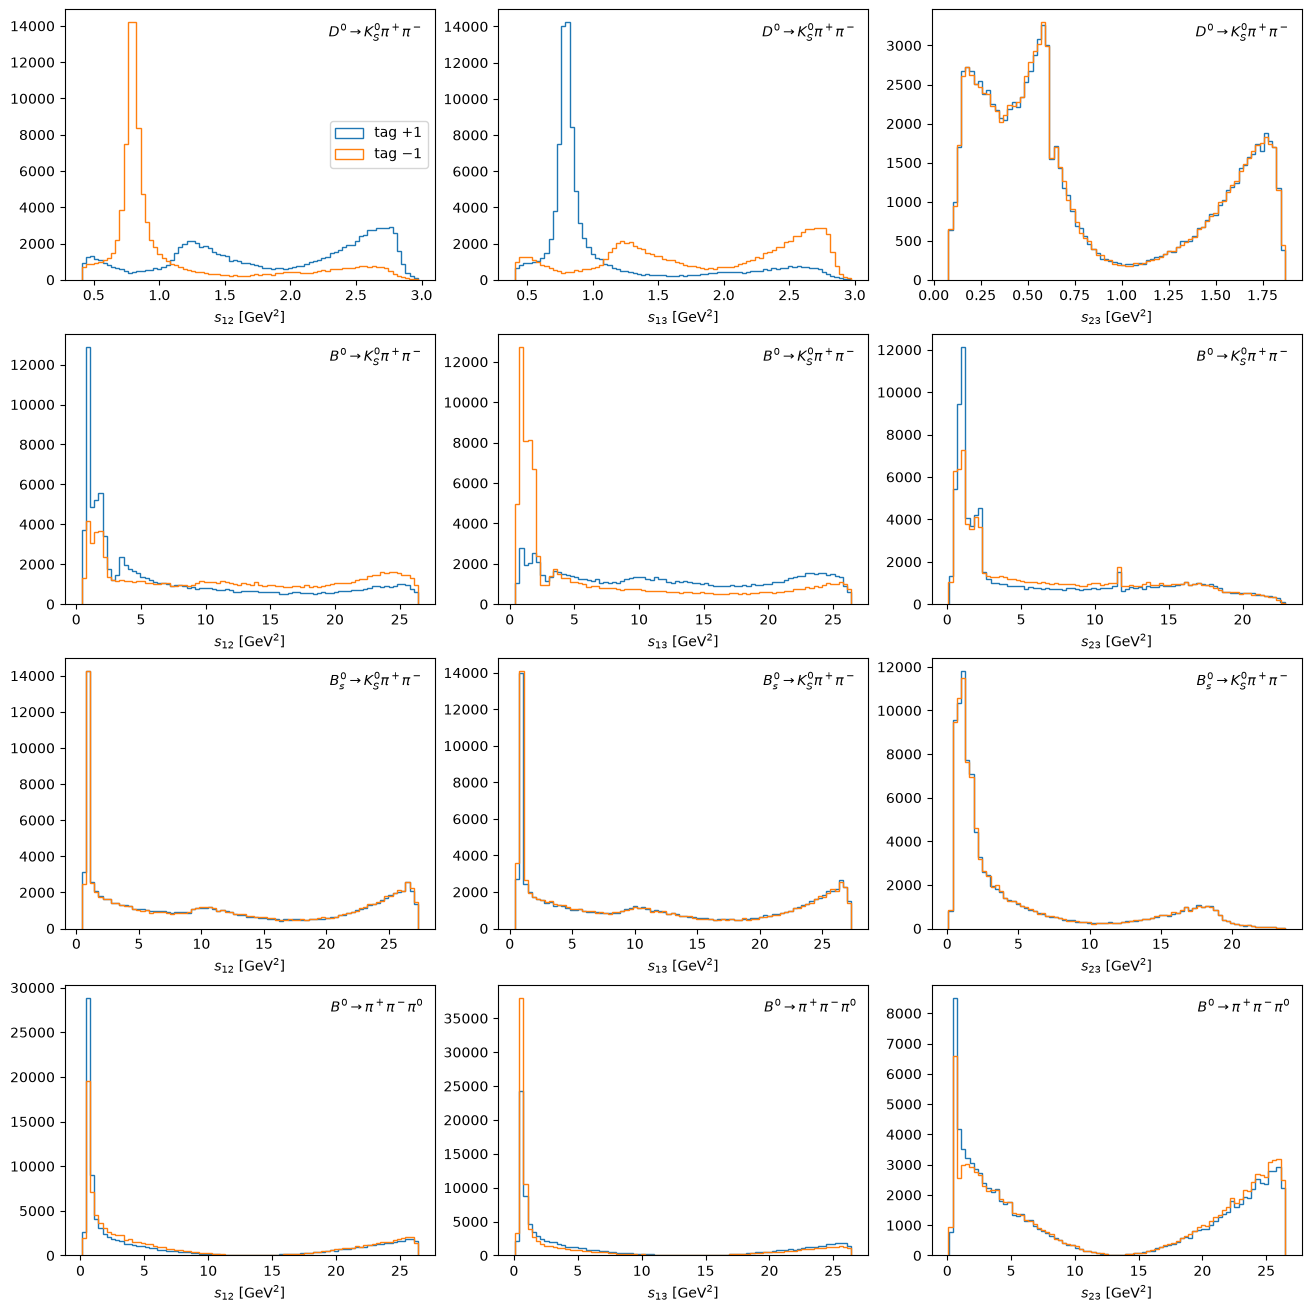

In [3]:
fig, ax = plt.subplots(len(CHANNELS), 3, figsize=(13, 13), layout="constrained")
for row, ch in zip(ax, CHANNELS):
    ev = events[ch]
    for a, s in zip(row, ("s12", "s13", "s23")):
        for t in (+1, -1):
            a.hist(ev[s][ev["tag"] == t], bins=80, histtype="step", label=f"tag ${t:+d}$")
        a.set(xlabel=f"${s[0]}_{{{s[1:]}}}$ [GeV$^2$]")
        decay_insert(a, ch)
ax[0, 0].legend()
plt.show()

## Time dependence over the whole Dalitz plot

The top row shows the decay time of each tag; the bottom row weights each event by
$e^{|\tau|}$, which removes the exponential and leaves the time dependence from
mixing.

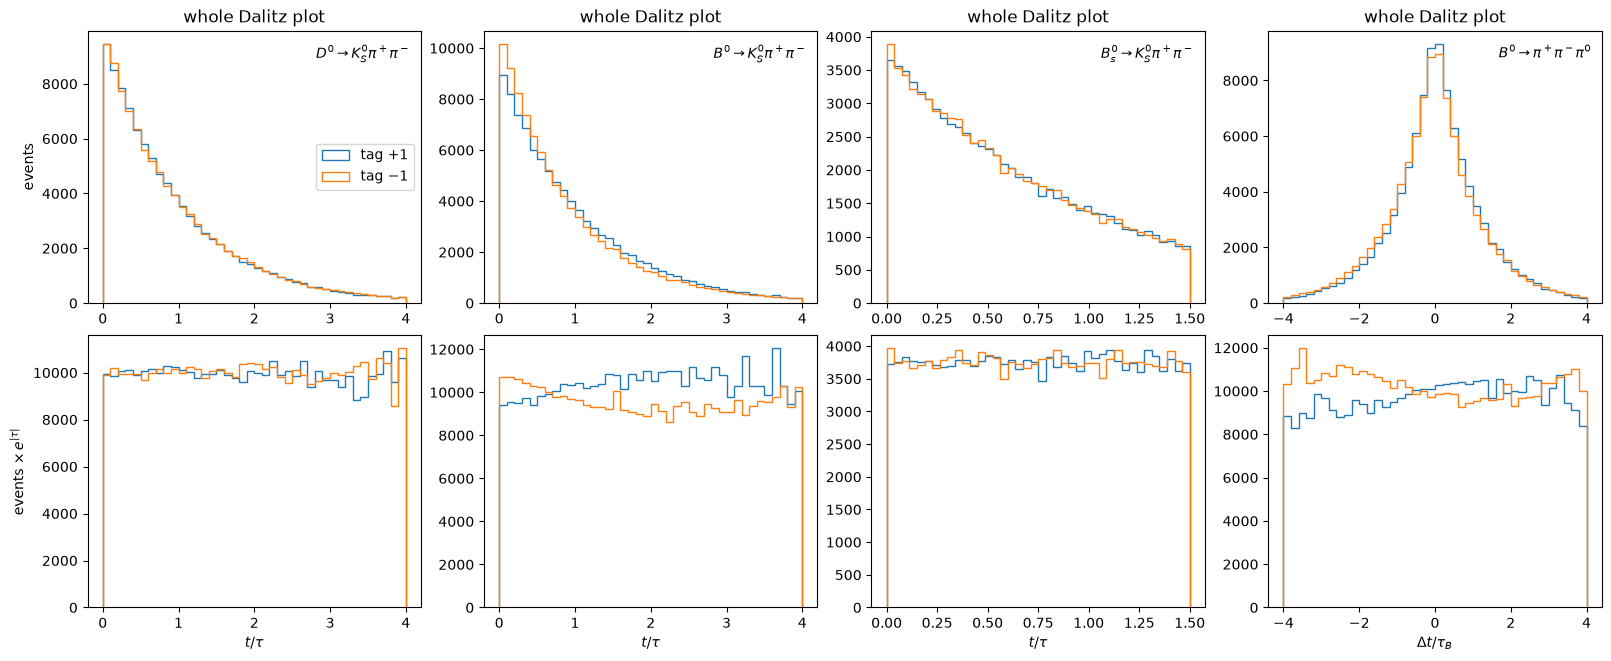

In [4]:
TIME = {"d0": (0, 4), "b0": (0, 4), "bs": (0, 1.5), "b0_3pi": (-4, 4)}   # bs oscillates fast

fig, ax = plt.subplots(2, len(CHANNELS), figsize=(16, 6.5), layout="constrained")
for col, ch in enumerate(CHANNELS):
    ev = events[ch]
    bins = np.linspace(*TIME[ch], 41)
    for t in (+1, -1):
        tau = ev["tau"][ev["tag"] == t]
        ax[0, col].hist(tau, bins, histtype="step", label=f"tag ${t:+d}$")
        ax[1, col].hist(tau, bins, weights=np.exp(np.abs(tau)), histtype="step")   # undo exp(-|tau|)
    ax[0, col].set_title("whole Dalitz plot")
    ax[1, col].set_xlabel(time_label(ev))
    decay_insert(ax[0, col], ch)
ax[0, 0].set_ylabel("events")
ax[1, 0].set_ylabel(r"events $\times\, e^{|\tau|}$")
ax[0, 0].legend()
plt.show()

## Isolating the time dependence: one resonance

The oscillation is much clearer where mostly one flavour decays, e.g. the $K^*(892)^+$ band of $B^0\to K_S^0\pi^+\pi^-$ (only $B^0\to K^{*+}\pi^-$ contributes). There the two tags follow $e^{-\tau}[1 \pm \cos(x\tau)]/2$. As above, the bottom row weights each event by $e^{|\tau|}$.

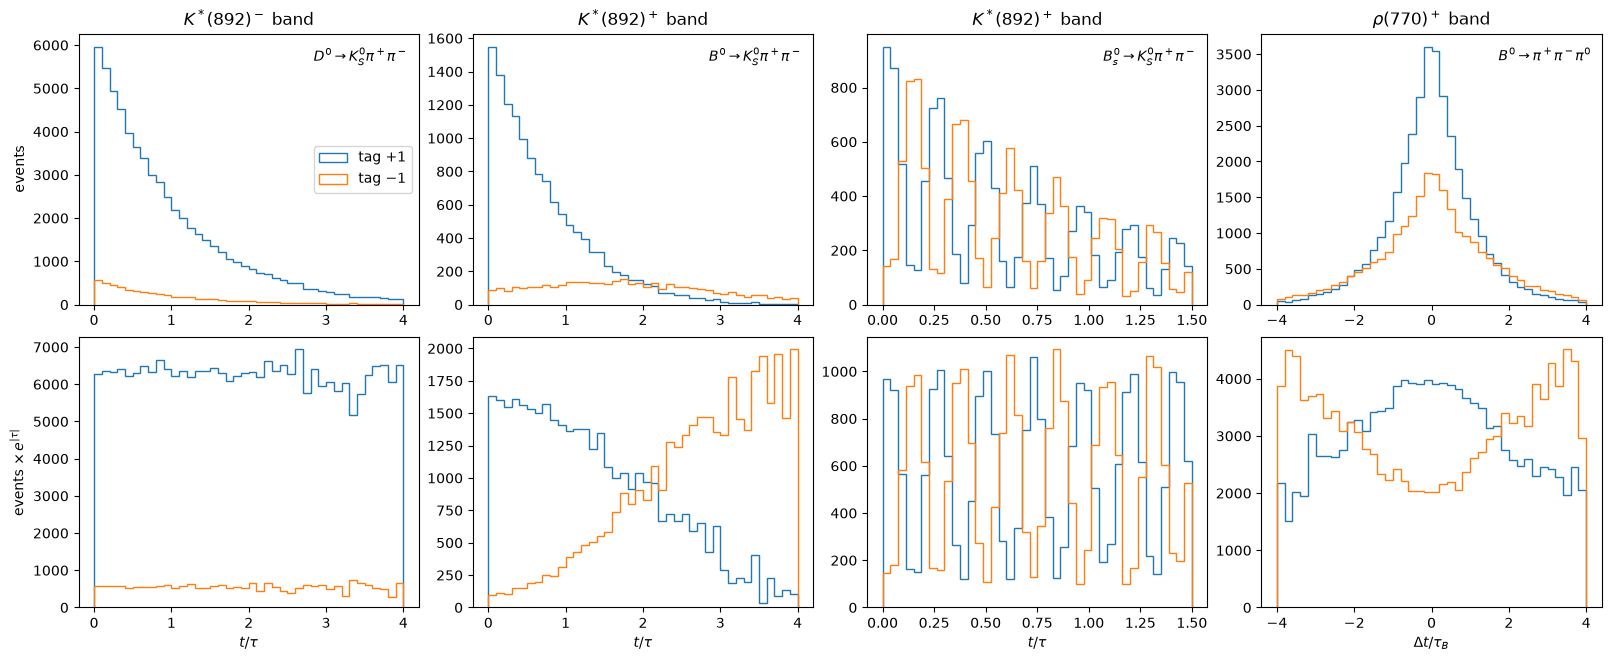

In [5]:
# A Dalitz band where mostly one flavour decays: (pair, low mass, high mass) in GeV
BAND = {"d0": ("s13", 0.80, 0.99, r"$K^*(892)^-$"), "b0": ("s12", 0.80, 0.99, r"$K^*(892)^+$"),
        "bs": ("s12", 0.80, 0.99, r"$K^*(892)^+$"), "b0_3pi": ("s12", 0.60, 0.95, r"$\rho(770)^+$")}
fig, ax = plt.subplots(2, len(CHANNELS), figsize=(16, 6.5), layout="constrained")
for col, ch in enumerate(CHANNELS):
    ev = events[ch]
    pair, lo, hi, name = BAND[ch]
    band = (np.sqrt(ev[pair]) > lo) & (np.sqrt(ev[pair]) < hi)
    bins = np.linspace(*TIME[ch], 41)
    for t in (+1, -1):
        tau = ev["tau"][band & (ev["tag"] == t)]
        ax[0, col].hist(tau, bins, histtype="step", label=f"tag ${t:+d}$")
        ax[1, col].hist(tau, bins, weights=np.exp(np.abs(tau)), histtype="step")   # undo exp(-|tau|)
    ax[0, col].set_title(f"{name} band")
    ax[1, col].set_xlabel(time_label(ev))
    decay_insert(ax[0, col], ch)
ax[0, 0].set_ylabel("events")
ax[1, 0].set_ylabel(r"events $\times\, e^{|\tau|}$")
ax[0, 0].legend()
plt.show()